# P4 — Best Picture Winners and IMDb Audience Ratings (2015–2024)
**DSA 405 | Project synthesis | Manika Jain**

**Question:** Among Best Picture nominees for film years 2015–2024, do winners have higher IMDb average audience ratings than non-winning nominees? This notebook rebuilds P3 from the original Wikipedia HTML and official IMDb TSV files, then adds P4 descriptive comparisons, within-year comparisons, figures, a data dictionary, and verification. **Do not interpret unmatched nominees as low-rated films.**

**Reproduction:** Run from repository root using `jupyter nbconvert --to notebook --execute DSA405_P4_FA26_mjain23.ipynb --output P4_executed.ipynb` after installing `requirements.txt`. First run downloads two large IMDb files (hundreds of MB compressed; much larger in memory). For first-time Wikipedia acquisition, set `WIKIMEDIA_CONTACT` to a genuine contact address or Wikimedia user page. IMDb source files must not be redistributed. A successful complete run has not been independently verified in this submission environment; check the assertions and exported results locally.

## 1. Provenance, access, and collection
Wikipedia contributors, [Best Picture article](https://en.wikipedia.org/wiki/Academy_Award_for_Best_Picture), CC BY-SA 4.0; [Wikimedia terms](https://foundation.wikimedia.org/wiki/Policy:Terms_of_Use). IMDb, [noncommercial datasets](https://developer.imdb.com/non-commercial-datasets/), subject to [IMDb terms](https://help.imdb.com/article/imdb/general-information/can-i-use-imdb-data-in-my-software/G5JTRESSHJBBHTGX). Information courtesy of IMDb (https://www.imdb.com). Used with permission. Review terms before fetching. The source IMDb files are not committed to the repository.

In [1]:
from pathlib import Path
from io import StringIO
import re, time, unicodedata
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser
import pandas as pd
import requests
import os

RAW = Path('data/raw'); RAW.mkdir(parents=True, exist_ok=True)
PROCESSED = Path('data/processed'); PROCESSED.mkdir(parents=True, exist_ok=True)
WIKI_URL = 'https://en.wikipedia.org/wiki/Academy_Award_for_Best_Picture'
IMDB_URLS = {
    'basics': 'https://datasets.imdbws.com/title.basics.tsv.gz',
    'ratings': 'https://datasets.imdbws.com/title.ratings.tsv.gz',
}
# Before a first-time download, supply an actual contact address or Wikimedia user page.
# An honest descriptive identifier is used for already-cached re-runs.
CONTACT = "mjain23@ncsu.edu"
HEADERS = {'User-Agent': f'NCSU-DSA405-BestPictureStudy/1.0 (contact: {CONTACT})' if CONTACT else 'NCSU-DSA405-BestPictureStudy/1.0 (contact missing)'}
REQUEST_GAP_SECONDS = 2.0
_last_request = None

def throttle():
    global _last_request
    if _last_request is not None:
        time.sleep(max(0.0, REQUEST_GAP_SECONDS - (time.monotonic() - _last_request)))
    _last_request = time.monotonic()

def cached_download(url, path, *, timeout=(15, 120)):
    """One request per uncached resource; stream to temporary file and rename only on success."""
    path = Path(path)
    if path.is_file() and path.stat().st_size > 0:
        print(f'CACHE HIT: {path} ({path.stat().st_size:,} bytes)')
        return path
    if path.exists():
        raise ValueError(f'Invalid empty cache file: {path}; investigate before retrying')
    if urlparse(url).hostname == 'en.wikipedia.org' and not CONTACT:
        raise ValueError('Before a new Wikimedia request, replace the User-Agent placeholder with an actual contact email or Wikimedia user page')
    throttle()
    temp = path.with_suffix(path.suffix + '.part')
    try:
        with requests.get(url, headers=HEADERS, stream=True, timeout=timeout) as response:
            response.raise_for_status()  # non-200 fails loudly
            with temp.open('wb') as f:
                for chunk in response.iter_content(chunk_size=1024*1024):
                    if chunk: f.write(chunk)
        if temp.stat().st_size == 0:
            raise ValueError(f'Empty response for {url}')
        temp.replace(path)
    except (requests.RequestException, OSError, ValueError) as exc:
        temp.unlink(missing_ok=True)
        raise RuntimeError(f'Acquisition failed for {url}: {exc}') from exc
    print(f'DOWNLOADED: {path} ({path.stat().st_size:,} bytes)')
    return path

### Cached robots check and access guard

In [2]:
# Fetch robots.txt once to the same raw cache and parse it locally.
robots_path = cached_download('https://en.wikipedia.org/robots.txt', RAW/'wikipedia_robots.txt')
rp = RobotFileParser()
rp.parse(robots_path.read_text(encoding='utf-8').splitlines())
allowed = rp.can_fetch(HEADERS['User-Agent'], WIKI_URL)
print('Wikipedia article permitted by cached robots.txt:', allowed)
if not allowed:
    raise PermissionError('Wikipedia robots.txt disallows this User-Agent/article path. Stop and consult instructor.')
print('Robots cache is a snapshot: review live rules before first download if an older cache is reused.')

CACHE HIT: data/raw/wikipedia_robots.txt (28,275 bytes)
Wikipedia article permitted by cached robots.txt: True
Robots cache is a snapshot: review live rules before first download if an older cache is reused.


### Wikipedia nominee extraction

In [3]:
wiki_path = cached_download(WIKI_URL, RAW/'wikipedia_best_picture.html')
html = wiki_path.read_text(encoding='utf-8')
if 'Best Picture' not in html:
    raise ValueError('Wikipedia response does not contain expected Best Picture text')
try:
    tables = pd.read_html(StringIO(html))
except ValueError as exc:
    raise ValueError('Wikipedia selector found no HTML tables; page structure may have changed') from exc
if not tables:
    raise ValueError('Wikipedia selector matched zero tables')
print('HTML tables found:', len(tables))

def flatten_columns(df):
    out = df.copy()
    out.columns = [' '.join(str(v) for v in c if str(v) != 'nan').strip() if isinstance(c, tuple)
                   else str(c).strip() for c in out.columns]
    return out

def find_exact_column(df, target):
    return next((c for c in df.columns if str(c).strip().lower() == target.lower()), None)

def select_award_tables(all_tables):
    """Fail loudly when required selectors are absent."""
    chosen = []
    for i, table in enumerate(all_tables):
        t = flatten_columns(table)
        film = find_exact_column(t, 'Film')
        year = find_exact_column(t, 'Year of film release')
        if film is not None and year is not None:
            chosen.append((i, t, film, year))
    if not chosen:
        raise ValueError('Selector matched nothing: no table with Film and Year of film release')
    return chosen

award_tables = select_award_tables(tables)
print('Best Picture table indexes:', [i for i, *_ in award_tables])
parts = []
for i, t, film, year in award_tables:
    x = pd.DataFrame({'film_year_raw': t[year].ffill(), 'title_raw': t[film], 'source_table': i})
    parts.append(x)
audit_raw = pd.concat(parts, ignore_index=True)
audit_raw['film_year'] = pd.to_numeric(audit_raw['film_year_raw'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')
project_raw = audit_raw.loc[audit_raw.film_year.between(2015, 2024)].copy()
if project_raw.empty:
    raise ValueError('No nominee records for 2015–2024; check Wikipedia structure')
print('Nominee rows before P2 cleaning:', len(project_raw))

CACHE HIT: data/raw/wikipedia_best_picture.html (1,016,474 bytes)
HTML tables found: 23
Best Picture table indexes: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Nominee rows before P2 cleaning: 91


### Nominee cleaning and winner assignment

In [4]:
nominees = project_raw.copy()
nominees['title'] = nominees['title_raw'].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
nominees = nominees.loc[nominees['title'].notna() & nominees['title'].ne('')].copy()
nominees['film_year'] = nominees['film_year'].astype(int)
duplicates_removed = int(nominees.duplicated(['film_year','title']).sum())
nominees = nominees.drop_duplicates(['film_year','title'], keep='first').sort_index().copy()

def normalize_title(series):
    return (series.astype('string').str.normalize('NFKC').str.lower()
            .str.replace(r'[’‘`]', "'", regex=True)
            .str.replace(r'[^a-z0-9]+', ' ', regex=True)
            .str.replace(r'\s+', ' ', regex=True).str.strip())
nominees['title_clean'] = normalize_title(nominees['title'])
nominees['award_year'] = nominees['film_year'] + 1
nominees['winner'] = ~nominees['film_year'].duplicated(keep='first')
nominees = nominees[['film_year','award_year','title','title_clean','winner']].reset_index(drop=True)
assert nominees.film_year.nunique() == 10, 'Missing one or more film years'
assert nominees.groupby('film_year').winner.sum().eq(1).all(), 'Expected exactly one winner per film year'
assert not nominees.duplicated(['film_year','title_clean']).any(), 'Normalized nominee keys are not unique'
print('P2-style cleaned nominees:', len(nominees), '| exact duplicates removed:', duplicates_removed)
display(nominees.groupby('film_year').agg(nominees=('title','size'), winners=('winner','sum')))

P2-style cleaned nominees: 91 | exact duplicates removed: 0


,nominees,winners
film_year,,
2015,8,1
2016,9,1
2017,9,1
2018,8,1
2019,9,1
2020,8,1
2021,10,1
2022,10,1
2023,10,1


### IMDb basics and ratings acquisition

In [5]:
basics_path = cached_download(IMDB_URLS['basics'], RAW/'title.basics.tsv.gz', timeout=(15, 300))
ratings_path = cached_download(IMDB_URLS['ratings'], RAW/'title.ratings.tsv.gz', timeout=(15, 300))
# Restrict to the columns needed for this research; source gzip files remain untouched.
basics = pd.read_csv(basics_path, sep='\t', compression='gzip', usecols=['tconst','titleType','primaryTitle','startYear'],
                     dtype='string', na_values=['\\N'], low_memory=False)
ratings = pd.read_csv(ratings_path, sep='\t', compression='gzip', usecols=['tconst','averageRating','numVotes'],
                      dtype={'tconst':'string','averageRating':'float64','numVotes':'Int64'}, na_values=['\\N'])
if basics.empty or ratings.empty:
    raise ValueError('IMDb file parsed to zero rows')
if basics.tconst.duplicated().any() or ratings.tconst.duplicated().any():
    raise ValueError('IMDb tconst identifiers unexpectedly duplicate')
print('IMDb basics:', len(basics), '| ratings:', len(ratings))

CACHE HIT: data/raw/title.basics.tsv.gz (230,199,655 bytes)
CACHE HIT: data/raw/title.ratings.tsv.gz (8,748,567 bytes)
IMDb basics: 12953566 | ratings: 1731454


## 2. Join: normalized title + film year; left join with one-to-one validation

In [6]:
expected_rows = len(nominees)  # expectation set BEFORE merge
print('Expected merged row count:', expected_rows)
movies = basics.loc[basics.titleType.eq('movie')].copy()
movies['film_year'] = pd.to_numeric(movies.startYear, errors='coerce').astype('Int64')
movies = movies.loc[movies.film_year.between(2015, 2024)].copy()
movies['title_clean'] = normalize_title(movies.primaryTitle)
# Only keys unique among IMDb movie records can be used as an unambiguous lookup.
key_cols = ['film_year','title_clean']
ambiguous = movies.loc[movies.duplicated(key_cols, keep=False), key_cols + ['tconst','primaryTitle']].copy()
ambiguous.to_csv(PROCESSED/'ambiguous_imdb_candidates.csv', index=False)
unique_movies = movies.loc[~movies.duplicated(key_cols, keep=False), ['film_year','title_clean','tconst','primaryTitle']].copy()
unique_movies = unique_movies.merge(ratings, on='tconst', how='left', validate='one_to_one')
# P3 core join: preserve every Wikipedia nominee and explicitly enforce one-to-one.
merged = nominees.merge(unique_movies, on=key_cols, how='left', validate='one_to_one', indicator=True)
print('Join outcome:')
print(merged['_merge'].value_counts().to_string())
print('Nominees without a unique IMDb title/year match:', int(merged.tconst.isna().sum()))
print('Nominees matched to IMDb but missing ratings:', int((merged.tconst.notna() & merged.averageRating.isna()).sum()))
merged.loc[merged.tconst.isna(), ['film_year','title','title_clean']].to_csv(PROCESSED/'unmatched_nominees.csv', index=False)
display(merged.loc[merged.tconst.isna(), ['film_year','title']])

Expected merged row count: 91
Join outcome:
_merge
both          86
left_only      5
right_only     0
Nominees without a unique IMDb title/year match: 5
Nominees matched to IMDb but missing ratings: 0


,film_year,title
0,2015,Spotlight
44,2020,The Father
45,2020,Judas and the Black Messiah
49,2020,Sound of Metal
77,2023,Maestro


### Structural verification

In [7]:
# Protects against fan-out: the merge must preserve all nominees.
assert len(merged) == expected_rows, "Join changed the row count"

# Protects against duplicate nominees after joining.
assert not merged.duplicated(
    ["film_year", "title_clean"]
).any(), "Duplicate nominee keys found"

# Protects against invalid IMDb ratings.
assert merged["averageRating"].dropna().between(
    1, 10
).all(), "IMDb ratings outside valid range"

# Protects against incorrect winner counts.
assert merged.groupby("film_year")["winner"].sum().eq(
    1
).all(), "Expected one winner per film year"

# Protects against lost nominee records.
assert merged["_merge"].ne("right_only").all(), \
    "Unexpected right-only records"

print("All five post-merge verification checks passed.")

All five post-merge verification checks passed.


### Independent winner identity checks

In [8]:
# Reference winners for the FILM years, not ceremony years.
expected_winners = {
    2015: 'Spotlight', 2016: 'Moonlight', 2017: 'The Shape of Water',
    2018: 'Green Book', 2019: 'Parasite', 2020: 'Nomadland',
    2021: 'CODA', 2022: 'Everything Everywhere All at Once',
    2023: 'Oppenheimer', 2024: 'Anora',
}
actual_winners = nominees.loc[nominees['winner']].set_index('film_year')['title'].to_dict()
for year, title in expected_winners.items():
    assert normalize_title(pd.Series([actual_winners.get(year, '')])).iloc[0] == normalize_title(pd.Series([title])).iloc[0], (year, actual_winners.get(year), title)
print('Winner identity checks passed for all 10 film years.')
display(pd.DataFrame({'film_year': list(expected_winners), 'verified_winner': list(expected_winners.values())}))

Winner identity checks passed for all 10 film years.


,film_year,verified_winner
0,2015,Spotlight
1,2016,Moonlight
2,2017,The Shape of Water
3,2018,Green Book
4,2019,Parasite
5,2020,Nomadland
6,2021,CODA
7,2022,Everything Everywhere All at Once
8,2023,Oppenheimer
9,2024,Anora


### Diagnose unresolved IMDb matches

In [9]:
unmatched = merged.loc[merged['tconst'].isna(), ['film_year','title','title_clean']].copy()
# Inspect ALL movie years, not just the 2015–2024 join window.
all_movies = basics.loc[basics.titleType.eq('movie'), ['tconst','primaryTitle','startYear']].copy()
all_movies['title_clean'] = normalize_title(all_movies['primaryTitle'])
candidates = unmatched.merge(all_movies, on='title_clean', how='left')
candidates['candidate_start_year'] = pd.to_numeric(candidates['startYear'], errors='coerce')
candidates['year_difference'] = candidates['candidate_start_year'] - candidates['film_year']
candidates['same_year'] = candidates['year_difference'].eq(0)
candidates = candidates.sort_values(['film_year','title','same_year','year_difference'], ascending=[True,True,False,True], na_position='last')
candidates.to_csv(PROCESSED/'unmatched_candidate_review.csv', index=False)
for (year,title), group in candidates.groupby(['film_year','title'], sort=True):
    print(f'\n{year}: {title} — {len(group)} same-title candidate row(s)')
    display(group[['tconst','primaryTitle','candidate_start_year','year_difference','same_year']].head(12))
print('Saved unmatched_candidate_review.csv; inspect candidate identities before accepting any manual crosswalk.')


2015: Spotlight — 2 same-title candidate row(s)


,tconst,primaryTitle,candidate_start_year,year_difference,same_year
0,tt1895587,Spotlight,2015,0,True
1,tt7785302,Spotlight,2015,0,True



2020: Judas and the Black Messiah — 1 same-title candidate row(s)


,tconst,primaryTitle,candidate_start_year,year_difference,same_year
15,tt9784798,Judas and the Black Messiah,2021,1,False



2020: Sound of Metal — 1 same-title candidate row(s)


,tconst,primaryTitle,candidate_start_year,year_difference,same_year
16,tt5363618,Sound of Metal,2019,-1,False



2020: The Father — 13 same-title candidate row(s)


,tconst,primaryTitle,candidate_start_year,year_difference,same_year
6,tt10272386,The Father,2020,0,True
10,tt16531196,The Father,2020,0,True
5,tt0296967,The Father,1947,-73,False
2,tt0069752,The Father,1971,-49,False
4,tt0148324,The Father,1975,-45,False
12,tt5049400,The Father,1979,-41,False
3,tt0117315,The Father,1996,-24,False
9,tt13765040,The Father,2015,-5,False
7,tt10409554,The Father,2019,-1,False
11,tt34392970,The Father,2026,6,False



2023: Maestro — 13 same-title candidate row(s)


,tconst,primaryTitle,candidate_start_year,year_difference,same_year
21,tt21970768,Maestro,2023,0,True
28,tt5535276,Maestro,2023,0,True
17,tt0368851,Maestro,2002,-21,False
18,tt11355356,Maestro,2002,-21,False
20,tt1785457,Maestro,2009,-14,False
23,tt3476480,Maestro,2014,-9,False
22,tt2261817,Maestro,2015,-8,False
24,tt3505800,Maestro!,2015,-8,False
19,tt13130400,Maestro,2021,-2,False
26,tt37179751,Maestro,2025,2,False


Saved unmatched_candidate_review.csv; inspect candidate identities before accepting any manual crosswalk.


### Intentional failure test: missing source columns

In [10]:
try:
    select_award_tables([pd.DataFrame({'Not Film': ['x'], 'Not Year': [2020]})])
except ValueError as exc:
    assert 'Selector matched nothing' in str(exc)
    print('EXPECTED FAILURE CAUGHT LOUDLY:', type(exc).__name__, '-', exc)
else:
    raise AssertionError('FAIL: selector returned silently on malformed input')

EXPECTED FAILURE CAUGHT LOUDLY: ValueError - Selector matched nothing: no table with Film and Year of film release


### Intentional failure test: duplicate join key

In [11]:
try:
    pd.DataFrame({'key':[1]}).merge(pd.DataFrame({'key':[1,1]}), on='key', validate='one_to_one')
except pd.errors.MergeError as exc:
    print('EXPECTED JOIN FAILURE CAUGHT:', type(exc).__name__, '-', exc)
else:
    raise AssertionError('FAIL: duplicate right keys were not rejected')

EXPECTED JOIN FAILURE CAUGHT: MergeError - Merge keys are not unique in right dataset; not a one-to-one merge


### Export audit artifacts

In [12]:
merged.to_csv(PROCESSED/'best_picture_imdb_joined.csv', index=False)
summary = pd.DataFrame([{
    'nominee_rows':len(nominees), 'joined_rows':len(merged),
    'matched_imdb_titles':int(merged.tconst.notna().sum()),
    'unmatched_titles':int(merged.tconst.isna().sum()),
    'rated_nominees':int(merged.averageRating.notna().sum()),
    'ambiguous_imdb_candidate_rows':len(ambiguous),
}])
summary.to_csv(PROCESSED/'join_summary.csv', index=False)
display(summary)
print('Saved processed files to', PROCESSED.resolve())

,nominee_rows,joined_rows,matched_imdb_titles,unmatched_titles,rated_nominees,ambiguous_imdb_candidate_rows
0,91,91,86,5,86,6357


Saved processed files to /content/data/processed


## 3. P4 analysis: ratings and missingness

IMDb `averageRating` is an aggregate of IMDb users' votes, **not** a representative population survey. Missing matches are excluded only from numerical rating comparisons and remain visible in the audit. Report winner and nonwinner sample sizes explicitly. A pooled comparison can differ from a within-film-year comparison; both are shown.

In [13]:
analysis = merged.loc[merged['averageRating'].notna()].copy()
analysis['averageRating'] = pd.to_numeric(analysis['averageRating'])
analysis['numVotes'] = pd.to_numeric(analysis['numVotes'])
counts = merged.groupby('winner').agg(total=('title','size'), rated=('averageRating','count')).rename(index={False:'Non-winners',True:'Winners'})
print('Rated coverage by winner status:')
display(counts)
summary_stats = analysis.groupby('winner').agg(n=('averageRating','size'), mean_rating=('averageRating','mean'), median_rating=('averageRating','median'), std_rating=('averageRating','std'), median_votes=('numVotes','median')).rename(index={False:'Non-winners',True:'Winners'})
display(summary_stats.round(3))
if analysis['winner'].nunique() != 2:
    raise ValueError('Need rated observations in both winner groups')
pooled_difference = analysis.loc[analysis.winner,'averageRating'].mean() - analysis.loc[~analysis.winner,'averageRating'].mean()
print(f'Pooled winner minus nonwinner mean rating: {pooled_difference:+.3f} IMDb points')
summary_stats.to_csv(PROCESSED/'rating_summary_by_winner.csv')
counts.to_csv(PROCESSED/'rating_coverage_by_winner.csv')

Rated coverage by winner status:


,total,rated
winner,,
Non-winners,81,77
Winners,10,9


,n,mean_rating,median_rating,std_rating,median_votes
winner,,,,,
Non-winners,77,7.556,7.6,0.460,291006.0
Winners,9,7.778,7.7,0.458,482454.0


Pooled winner minus nonwinner mean rating: +0.222 IMDb points


### Within-year comparison: winner rating minus mean rated nonwinner rating

In [14]:
year_rows=[]
for year, g in merged.groupby('film_year'):
    w = g.loc[g.winner,'averageRating'].dropna()
    nw = g.loc[~g.winner,'averageRating'].dropna()
    year_rows.append({'film_year':int(year), 'winner_title':g.loc[g.winner,'title'].iloc[0],
        'winner_rating':float(w.iloc[0]) if len(w) else float('nan'),
        'nonwinner_mean':float(nw.mean()) if len(nw) else float('nan'),
        'rated_nonwinners':len(nw), 'unmatched_nominees':int(g.averageRating.isna().sum()),
        'difference':float(w.iloc[0]-nw.mean()) if len(w) and len(nw) else float('nan')})
by_year=pd.DataFrame(year_rows)
display(by_year.round(3))
valid=by_year.dropna(subset=['difference'])
print(f'Years with a usable winner/nonwinner comparison: {len(valid)}/10')
print(f'Years with winner rating above rated nonwinner mean: {(valid.difference>0).sum()}/{len(valid)}')
print(f'Average of within-year differences: {valid.difference.mean():+.3f}' if len(valid) else 'No valid year comparisons')
by_year.to_csv(PROCESSED/'within_year_comparison.csv',index=False)
assert len(by_year)==10
assert len(merged)==91
assert merged['averageRating'].notna().sum() + merged['averageRating'].isna().sum()==len(merged)

,film_year,winner_title,winner_rating,nonwinner_mean,rated_nonwinners,unmatched_nominees,difference
0,2015,Spotlight,NaN,7.871,7,1,NaN
1,2016,Moonlight,7.4,7.800,8,0,-0.400
2,2017,The Shape of Water,7.3,7.612,8,0,-0.312
3,2018,Green Book,8.2,7.514,7,0,0.686
4,2019,Parasite,8.5,7.938,8,0,0.562
5,2020,Nomadland,7.3,7.350,4,3,-0.050
6,2021,CODA,8.0,7.256,9,0,0.744
7,2022,Everything Everywhere All at Once,7.7,7.489,9,0,0.211
8,2023,Oppenheimer,8.2,7.512,8,1,0.688
9,2024,Anora,7.4,7.233,9,0,0.167


Years with a usable winner/nonwinner comparison: 9/10
Years with winner rating above rated nonwinner mean: 6/9
Average of within-year differences: +0.255


### Figures

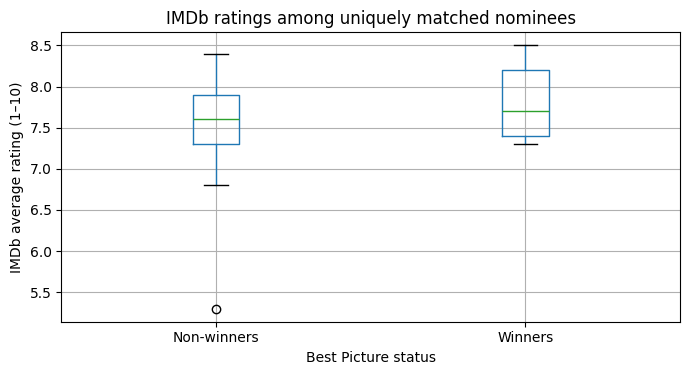

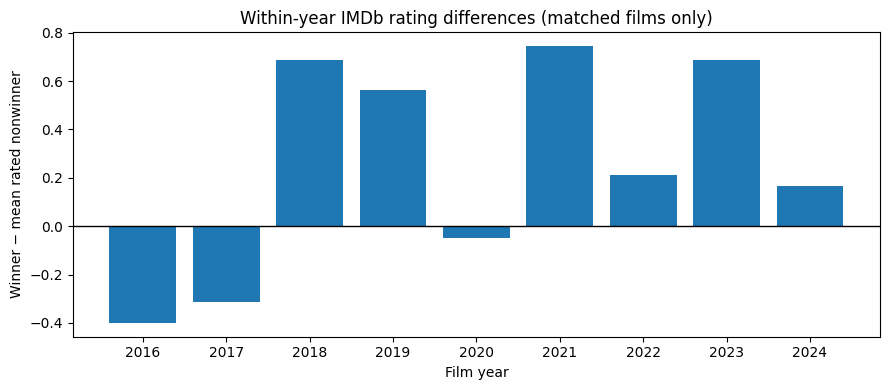

In [15]:
import matplotlib.pyplot as plt
FIGURES=Path('figures');FIGURES.mkdir(exist_ok=True)
fig,ax=plt.subplots(figsize=(7,4))
analysis.boxplot(column='averageRating',by='winner',ax=ax)
ax.set_xticklabels(['Non-winners','Winners']);ax.set_xlabel('Best Picture status');ax.set_ylabel('IMDb average rating (1–10)');ax.set_title('IMDb ratings among uniquely matched nominees')
fig.suptitle('');fig.tight_layout();fig.savefig(FIGURES/'rating_boxplot.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(valid.film_year.astype(str),valid.difference)
ax.axhline(0,color='black',linewidth=1);ax.set_xlabel('Film year');ax.set_ylabel('Winner − mean rated nonwinner');ax.set_title('Within-year IMDb rating differences (matched films only)')
fig.tight_layout();fig.savefig(FIGURES/'within_year_differences.png',dpi=160);plt.show()

### Missingness sensitivity: why exclusions matter

In [16]:
missing = merged.loc[merged.averageRating.isna(), ['film_year','title','winner']].copy()
display(missing)
print('Winner missing ratings:', int(missing.winner.sum()))
print('Nonwinner missing ratings:', int((~missing.winner).sum()))
print('Because IMDb ratings for these titles are unknown in this join, the complete-population mean difference cannot be established from matched rows alone.')
missing.to_csv(PROCESSED/'missing_rating_cases.csv',index=False)

,film_year,title,winner
0,2015,Spotlight,True
44,2020,The Father,False
45,2020,Judas and the Black Messiah,False
49,2020,Sound of Metal,False
77,2023,Maestro,False


Winner missing ratings: 1
Nonwinner missing ratings: 4
Because IMDb ratings for these titles are unknown in this join, the complete-population mean difference cannot be established from matched rows alone.


### Final dictionary, data checks, and machine-readable run summary

In [17]:
definitions={'film_year':'Year of film release used for Oscar nomination grouping','award_year':'Film year + 1 (ceremony year)','title':'Wikipedia film title, whitespace normalized','title_clean':'Normalized join title: NFKC, lowercase, punctuation removed','winner':'Best Picture winner flag, verified against ten named winners','tconst':'IMDb unique title identifier; missing when no unique title/year match','primaryTitle':'IMDb primary title for matched record','averageRating':'IMDb aggregate user rating, scale 1–10','numVotes':'Number of IMDb votes in snapshot','_merge':'Pandas join provenance indicator'}
dictionary=pd.DataFrame([{'variable':c,'dtype':str(merged[c].dtype),'missing_n':int(merged[c].isna().sum()),'description':definitions.get(c,'IMDb / integration field; see source code')} for c in merged.columns])
display(dictionary);dictionary.to_csv(PROCESSED/'final_data_dictionary.csv',index=False)
assert len(merged)==len(nominees)
assert merged.groupby('film_year').winner.sum().eq(1).all()
assert not merged.duplicated(['film_year','title_clean']).any()
assert merged.averageRating.dropna().between(1,10).all()
print('Final assertions passed.')
run_summary={'nominees':int(len(merged)),'matched_ratings':int(merged.averageRating.notna().sum()),'unmatched':int(merged.averageRating.isna().sum()),'winner_minus_nonwinner_mean':float(pooled_difference),'usable_years':int(len(valid)),'mean_within_year_difference':float(valid.difference.mean()) if len(valid) else None}
import json
(PROCESSED/'p4_run_summary.json').write_text(json.dumps(run_summary,indent=2))
print(json.dumps(run_summary,indent=2))

,variable,dtype,missing_n,description
0,film_year,int64,0,Year of film release used for Oscar nomination...
1,award_year,int64,0,Film year + 1 (ceremony year)
2,title,string,0,"Wikipedia film title, whitespace normalized"
3,title_clean,string,0,"Normalized join title: NFKC, lowercase, punctu..."
4,winner,bool,0,"Best Picture winner flag, verified against ten..."
5,tconst,string,5,IMDb unique title identifier; missing when no ...
6,primaryTitle,string,5,IMDb primary title for matched record
7,averageRating,float64,5,"IMDb aggregate user rating, scale 1–10"
8,numVotes,Int64,5,Number of IMDb votes in snapshot
9,_merge,category,0,Pandas join provenance indicator


Final assertions passed.
{
  "nominees": 91,
  "matched_ratings": 86,
  "unmatched": 5,
  "winner_minus_nonwinner_mean": 0.22193362193362276,
  "usable_years": 9,
  "mean_within_year_difference": 0.25504850088183406
}


## 4. Interpretation and reproducibility caveats

The computed comparisons describe **IMDb users' ratings for uniquely matched titles in this particular dataset snapshot**, not all moviegoers, not causal effects of winning, and not the Academy's preferences. Inspect the five unmatched nominees and candidate review file before generalizing. IMDb ratings and Wikipedia tables can change; save a dated local run log, but do not publish restricted IMDb raw/derived records. An external reader needs to download the IMDb source files themselves. No manual crosswalk was added without independent verification.